In [2]:
import pandas as pd

path = "../data/raw/CanadaTrades.csv"

df = pd.read_csv(path, encoding="utf-8-sig")
print(df.shape)

(8736, 17)


In [3]:
print(df.columns.tolist())
df.head(10)

['REF_DATE', 'GEO', 'DGUID', 'Trade', 'North American Product Classification System (NAPCS)', 'Principal trading partners', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']


,REF_DATE,GEO,DGUID,Trade,North American Product Classification System (NAPCS),Principal trading partners,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,2022-01,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,48967624,NaN,NaN,NaN,0
1,2022-02,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,51187677,NaN,NaN,NaN,0
2,2022-03,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,66015296,NaN,NaN,NaN,0
3,2022-04,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,63048344,NaN,NaN,NaN,0
4,2022-05,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,63984238,NaN,NaN,NaN,0
5,2022-06,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,67037435,NaN,NaN,NaN,0
6,2022-07,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,62517645,NaN,NaN,NaN,0
7,2022-08,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,67054065,NaN,NaN,NaN,0
8,2022-09,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,65478079,NaN,NaN,NaN,0
9,2022-10,Canada,2021A000011124,Import,Total of all merchandise,All countries,Dollars,81,thousands,3,v1567082903,1.1.1.1,66586363,NaN,NaN,NaN,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8736 entries, 0 to 8735
Data columns (total 17 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   REF_DATE                                              8736 non-null   str    
 1   GEO                                                   8736 non-null   str    
 2   DGUID                                                 8736 non-null   str    
 3   Trade                                                 8736 non-null   str    
 4   North American Product Classification System (NAPCS)  8736 non-null   str    
 5   Principal trading partners                            8736 non-null   str    
 6   UOM                                                   8736 non-null   str    
 7   UOM_ID                                                8736 non-null   int64  
 8   SCALAR_FACTOR                                         8736 non-null  

In [5]:
for col in ["GEO", "Trade", "Principal trading partners",
            "North American Product Classification System (NAPCS)"]:
    print(col)
    print(df[col].unique())
    print()

print("Months:", df["REF_DATE"].nunique(), 
      "| from", df["REF_DATE"].min(), "to", df["REF_DATE"].max())

GEO
<StringArray>
['Canada', 'Quebec', 'Ontario']
Length: 3, dtype: str

Trade
<StringArray>
['Import', 'Domestic export']
Length: 2, dtype: str

Principal trading partners
<StringArray>
['All countries', 'United States']
Length: 2, dtype: str

North American Product Classification System (NAPCS)
<StringArray>
[                                        'Total of all merchandise',
               'Farm, fishing and intermediate food products [C11]',
                                            'Energy products [C12]',
                       'Metal ores and non-metallic minerals [C13]',
                    'Metal and non-metallic mineral products [C14]',
 'Basic and industrial chemical, plastic and rubber products [C15]',
     'Forestry products and building and packaging materials [C16]',
                  'Industrial machinery, equipment and parts [C17]',
              'Electronic and electrical equipment and parts [C18]',
                                   'Motor vehicles and parts [C19]'

In [6]:
prod_col = "North American Product Classification System (NAPCS)"

# Convert date text to a real date, and thousands to dollars
df["date"] = pd.to_datetime(df["REF_DATE"])
df["value_cad"] = df["VALUE"] * 1000

keys = ["date", "GEO", "Trade", "Principal trading partners"]

total = (df[df[prod_col] == "Total of all merchandise"]
         .set_index(keys)["value_cad"].rename("total"))

sections_sum = (df[df[prod_col] != "Total of all merchandise"]
                .groupby(keys)["value_cad"].sum().rename("sections_sum"))

chk = pd.concat([total, sections_sum], axis=1)
chk["diff_pct"] = (chk["sections_sum"] - chk["total"]) / chk["total"] * 100

chk["diff_pct"].describe()

count    6.720000e+02
mean    -1.855619e-07
std      1.222129e-05
min     -7.465258e-05
25%     -2.554546e-06
50%      0.000000e+00
75%      2.293661e-06
max      7.894797e-05
Name: diff_pct, dtype: float64

Matplotlib is building the font cache; this may take a moment.


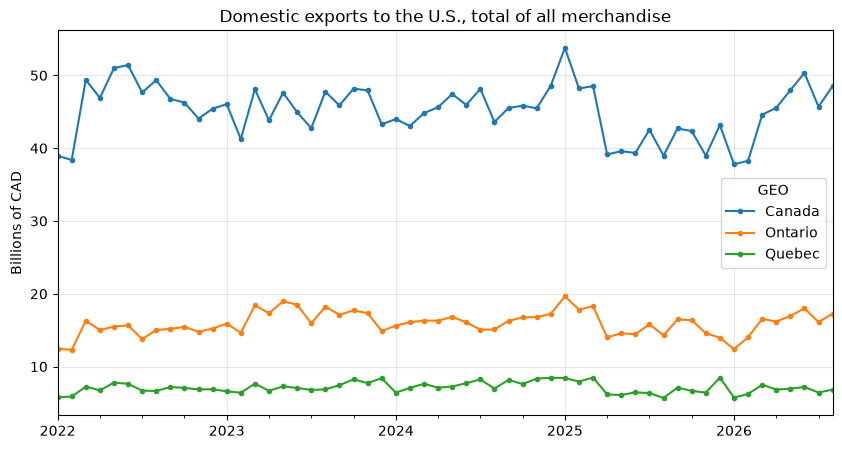

In [7]:
import matplotlib.pyplot as plt

exp_us = df[
    (df["Trade"] == "Domestic export")
    & (df["Principal trading partners"] == "United States")
    & (df[prod_col] == "Total of all merchandise")
]

pivot = exp_us.pivot(index="date", columns="GEO", values="value_cad") / 1e9

pivot.plot(figsize=(10, 5), marker="o", markersize=3)
plt.title("Domestic exports to the U.S., total of all merchandise")
plt.ylabel("Billions of CAD")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.show()

In [8]:
ytd = exp_us[exp_us['date'].dt.month <= 8].copy()
ytd['year'] = ytd['date'].dt.year

ytd_tot = (ytd.groupby(['GEO', 'year'])['value_cad'].sum()
              .unstack('year') / 1e9)

print('Jan-Aug totals, billions CAD')
print(ytd_tot.round(1))

print('\nYear-over-year change, %')
print((ytd_tot.pct_change(axis=1) * 100).round(1))

Jan-Aug totals, billions CAD
year      2022   2023   2024   2025   2026
GEO                                       
Canada   373.1  362.3  362.6  350.1  358.7
Ontario  116.0  137.9  127.4  128.9  127.5
Quebec    54.4   55.4   58.4   55.6   53.8

Year-over-year change, %
year     2022  2023  2024  2025  2026
GEO                                  
Canada    NaN  -2.9   0.1  -3.5   2.5
Ontario   NaN  18.9  -7.6   1.2  -1.1
Quebec    NaN   1.7   5.5  -4.8  -3.4


In [9]:
df['section'] = df[prod_col].str.extract(r'\[(C\d+)\]')[0].fillna('Total')

base = df[(df['Trade'] == 'Domestic export')
          & (df['Principal trading partners'] == 'United States')
          & (df['date'].dt.month <= 8)].copy()
base['year'] = base['date'].dt.year

by_sec = (base.groupby(['GEO', 'section', 'year'])['value_cad'].sum()
              .unstack('year') / 1e9)

for geo in ['Quebec', 'Ontario']:
    t = by_sec.loc[geo].drop('Total')
    print(geo, '- Jan-Aug exports to the U.S., billions CAD')
    print(t.round(2))
    chg = pd.DataFrame({
        '2025 vs 2024 %': (t[2025] / t[2024] - 1) * 100,
        '2026 vs 2024 %': (t[2026] / t[2024] - 1) * 100,
    }).round(1)
    print(chg.sort_values('2026 vs 2024 %'))
    print()

Quebec - Jan-Aug exports to the U.S., billions CAD
year      2022   2023   2024   2025   2026
section                                   
C11       1.50   1.46   1.43   1.50   1.63
C12       3.74   3.53   2.92   2.54   3.73
C13       0.59   0.54   0.57   0.46   0.52
C14      13.98  13.13  13.46  12.94  12.45
C15       3.73   3.87   3.80   3.01   3.33
C16       9.19   7.77   7.82   7.39   7.05
C17       3.43   3.79   4.05   3.88   3.83
C18       2.74   2.58   2.97   3.15   2.78
C19       2.12   3.08   4.17   3.40   2.18
C21       4.53   6.14   6.99   6.94   6.26
C22       8.40   8.87   9.62   9.71   9.28
C23       0.47   0.58   0.62   0.71   0.72
         2025 vs 2024 %  2026 vs 2024 %
section                                
C19               -18.5           -47.7
C15               -20.8           -12.5
C21                -0.7           -10.4
C16                -5.4            -9.8
C13               -19.6            -8.7
C14                -3.9            -7.5
C18                 5.9    

In [10]:
meta_path = '../data/raw/CanadaTrades_Metadata.csv'

with open(meta_path, encoding='utf-8-sig') as f:
    lines = f.read().splitlines()

print('Total lines:', len(lines))
print()

keywords = ['province', 'clearance', 'origin', 'customs', 'seasonal', 'revis']
for i, line in enumerate(lines):
    if any(k in line.lower() for k in keywords):
        print(i, '|', line[:300])

Total lines: 104

1 | "International merchandise trade by province, commodity, and Principal Trading Partners","12100175",,"https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=1210017501",1;2;3;4;5;6,"CURRENT - a cube available to the public and that is current","Monthly","1997-01-01","2026-08-01","4",
85 | "revised","r",
90 | "2201","Canadian International Merchandise Trade (Customs Basis)"
98 | 3,"Domestic exports are goods grown, produced, extracted, or manufactured in Canada, including goods of foreign origin that have been materially transformed in Canada."
99 | 4,"Imports are goods that have entered the country by crossing territorial boundaries. Imports in this table are based on the province of clearance concept, which is the Canadian province (or territory) where the goods cleared customs. This may not always be the province (or territory) in which the 
100 | 5,"Re-exports are goods of foreign origin which are exported in either the same condition in which they were original

In [11]:
for i in range(94, 104):
    print(i, '|', lines[i])
    print()

94 | 

95 | "Note ID",Note

96 | 1,"This cube replaces archived cube 12-10-0119-01."

97 | 2,"For more information related to the North American Product Classification System (NAPCS) 2022, please use the following <a href="http://www.statcan.gc.ca/eng/subjects/standard/napcs/2022/index" rel="external noopener noreferrer" target="_blank">hyperlink (opens new window)</a>."

98 | 3,"Domestic exports are goods grown, produced, extracted, or manufactured in Canada, including goods of foreign origin that have been materially transformed in Canada."

99 | 4,"Imports are goods that have entered the country by crossing territorial boundaries. Imports in this table are based on the province of clearance concept, which is the Canadian province (or territory) where the goods cleared customs. This may not always be the province (or territory) in which the goods are consumed."

100 | 5,"Re-exports are goods of foreign origin which are exported in either the same condition in which they were original

In [12]:
df['section'] = df[prod_col].str.extract(r'\[(C\d+)\]')[0].fillna('Total')

base = df[(df['Trade'] == 'Domestic export')
          & (df['Principal trading partners'] == 'United States')
          & (df['date'].dt.month <= 8)].copy()
base['year'] = base['date'].dt.year

by_sec = (base.groupby(['GEO', 'section', 'year'])['value_cad'].sum()
              .unstack('year') / 1e9)

for geo in ['Quebec', 'Ontario']:
    t = by_sec.loc[geo].drop('Total')
    print(geo, '- Jan-Aug exports to the U.S., billions CAD')
    print(t.round(2))
    chg = pd.DataFrame({
        '2025 vs 2024 %': (t[2025] / t[2024] - 1) * 100,
        '2026 vs 2024 %': (t[2026] / t[2024] - 1) * 100,
    }).round(1)
    print(chg.sort_values('2026 vs 2024 %'))
    print()

Quebec - Jan-Aug exports to the U.S., billions CAD
year      2022   2023   2024   2025   2026
section                                   
C11       1.50   1.46   1.43   1.50   1.63
C12       3.74   3.53   2.92   2.54   3.73
C13       0.59   0.54   0.57   0.46   0.52
C14      13.98  13.13  13.46  12.94  12.45
C15       3.73   3.87   3.80   3.01   3.33
C16       9.19   7.77   7.82   7.39   7.05
C17       3.43   3.79   4.05   3.88   3.83
C18       2.74   2.58   2.97   3.15   2.78
C19       2.12   3.08   4.17   3.40   2.18
C21       4.53   6.14   6.99   6.94   6.26
C22       8.40   8.87   9.62   9.71   9.28
C23       0.47   0.58   0.62   0.71   0.72
         2025 vs 2024 %  2026 vs 2024 %
section                                
C19               -18.5           -47.7
C15               -20.8           -12.5
C21                -0.7           -10.4
C16                -5.4            -9.8
C13               -19.6            -8.7
C14                -3.9            -7.5
C18                 5.9    

In [13]:
t = by_sec.loc['Ontario'].drop('Total')
t['avg_22_24'] = t[[2022, 2023, 2024]].mean(axis=1)

out = pd.DataFrame({
    '2022': t[2022], '2023': t[2023], '2024': t[2024],
    '2025': t[2025], '2026': t[2026],
    '2025 vs avg %': (t[2025] / t['avg_22_24'] - 1) * 100,
    '2026 vs avg %': (t[2026] / t['avg_22_24'] - 1) * 100,
}).round(2)

print(out.to_string())

          2022   2023   2024   2025   2026  2025 vs avg %  2026 vs avg %
section                                                                 
C11       3.58   4.26   4.30   4.31   4.72           6.45          16.78
C12       2.33   1.75   1.75   1.87   2.16          -4.12          10.98
C13       0.25   0.25   0.26   0.30   0.32          17.78          24.43
C14      16.57  21.00  15.81  18.49  14.19           3.92         -20.25
C15       9.89   9.63   9.45   8.76   9.53          -9.28          -1.27
C16       8.46   7.98   8.31   8.00   7.80          -3.01          -5.45
C17      10.43  12.20  11.50  11.65  12.19           2.38           7.13
C18       5.21   6.20   6.45   6.63   8.16          11.42          37.10
C19      36.27  47.89  43.26  41.62  38.69          -2.02          -8.91
C21       1.39   2.03   1.97   1.83   2.29           2.28          27.60
C22      20.03  22.77  22.42  23.02  24.52           5.87          12.78
C23       1.63   1.97   1.94   2.44   2.95         

In [14]:
rows = {}
for geo in ['Quebec', 'Ontario']:
    t = by_sec.loc[geo].drop('Total')
    b1 = t[[2022, 2023, 2024]].mean(axis=1)
    b2 = t[[2023, 2024]].mean(axis=1)
    rows[geo] = pd.DataFrame({
        '2026 vs avg22-24 %': (t[2026] / b1 - 1) * 100,
        '2026 vs avg23-24 %': (t[2026] / b2 - 1) * 100,
    }).round(1)

print(pd.concat(rows, axis=1).to_string())

                    Quebec                               Ontario                   
        2026 vs avg22-24 % 2026 vs avg23-24 % 2026 vs avg22-24 % 2026 vs avg23-24 %
section                                                                            
C11                   10.8               12.2               16.8               10.4
C12                    9.8               15.7               11.0               23.3
C13                   -7.9               -6.1               24.4               23.1
C14                   -8.0               -6.4              -20.2              -22.9
C15                  -12.4              -13.3               -1.3               -0.0
C16                  -14.6               -9.5               -5.4               -4.2
C17                    1.9               -2.4                7.1                2.8
C18                    0.6                0.1               37.1               29.0
C19                  -30.2              -39.9               -8.9            

In [5]:
import pandas as pd

df = pd.read_csv('../data/raw/CanadaTrades.csv', encoding='utf-8-sig')

prod_col = 'North American Product Classification System (NAPCS)'

df['date'] = pd.to_datetime(df['REF_DATE'])
df['value_cad'] = df['VALUE'] * 1000
df['section'] = df[prod_col].str.extract(r'\[(C\d+)\]')[0].fillna('Total')

print(df.shape)

(8736, 20)


In [6]:
print(prod_col in df.columns, df['date'].min(), df['date'].max())

True 2022-01-01 00:00:00 2026-08-01 00:00:00


In [8]:
exp = df[(df['Trade'] == 'Domestic export')
         & (df[prod_col] == 'Total of all merchandise')]

p = exp.pivot_table(index=['date', 'GEO'],
                    columns='Principal trading partners',
                    values='value_cad').reset_index()

p['non_us'] = p['All countries'] - p['United States']
p['year'] = p['date'].dt.year
p['month'] = p['date'].dt.month

ytd = (p[p['month'] <= 8]
       .groupby(['GEO', 'year'])[['United States', 'non_us', 'All countries']]
       .sum() / 1e9)
ytd['US share %'] = ytd['United States'] / ytd['All countries'] * 100

print('Jan-Aug domestic exports, billions CAD')
print(ytd.round(1))

print('\nYear-over-year change, %')
print((ytd[['United States', 'non_us']]
       .groupby('GEO').pct_change() * 100).round(1))

Jan-Aug domestic exports, billions CAD
Principal trading partners  United States  non_us  All countries  US share %
GEO     year                                                                
Canada  2022                        373.1   112.7          485.8        76.8
        2023                        362.3   107.7          470.0        77.1
        2024                        362.6   112.4          475.0        76.3
        2025                        350.1   125.6          475.7        73.6
        2026                        358.7   169.9          528.6        67.9
Ontario 2022                        116.0    36.1          152.2        76.3
        2023                        137.9    30.6          168.6        81.8
        2024                        127.4    38.2          165.6        76.9
        2025                        128.9    44.7          173.6        74.3
        2026                        127.5    71.4          198.9        64.1
Quebec  2022                         

In [9]:
sec = df[(df['Trade'] == 'Domestic export')
         & (df['section'] != 'Total')
         & (df['date'].dt.month <= 8)].copy()
sec['year'] = sec['date'].dt.year

q = (sec.pivot_table(index=['GEO', 'section', 'year'],
                     columns='Principal trading partners',
                     values='value_cad', aggfunc='sum') / 1e9)
q['non_us'] = q['All countries'] - q['United States']
nu = q['non_us'].unstack('year')

for geo in ['Ontario', 'Quebec']:
    t = nu.loc[geo]
    out = pd.DataFrame({'2024': t[2024],
                        '2026': t[2026],
                        'change': t[2026] - t[2024]}).round(2)
    print(geo, '- non-U.S. domestic exports, Jan-Aug, billions CAD')
    print(out.sort_values('change', ascending=False))
    print()

Ontario - non-U.S. domestic exports, Jan-Aug, billions CAD
          2024   2026  change
section                      
C14      20.86  52.67   31.81
C22       4.55   5.36    0.81
C18       2.03   2.32    0.29
C15       1.23   1.51    0.28
C19       2.18   2.43    0.25
C13       0.25   0.44    0.18
C17       2.39   2.50    0.11
C23       0.10   0.12    0.02
C16       0.34   0.33   -0.00
C12       0.44   0.43   -0.01
C11       2.01   1.86   -0.15
C21       1.80   1.39   -0.41

Quebec - non-U.S. domestic exports, Jan-Aug, billions CAD
         2024  2026  change
section                    
C21      3.41  4.67    1.26
C14      2.44  3.61    1.17
C12      0.33  1.35    1.01
C19      0.76  1.13    0.37
C18      1.28  1.55    0.27
C17      1.53  1.78    0.25
C22      2.28  2.36    0.08
C15      0.77  0.81    0.04
C23      0.53  0.54    0.01
C13      4.17  4.17   -0.00
C11      0.88  0.80   -0.08
C16      1.06  0.77   -0.29



Principal trading partners  All countries  United States  non_us
date                                                            
2024-03-01                           4.64           1.94    2.70
2024-04-01                           4.71           2.10    2.61
2024-05-01                           3.90           2.22    1.68
2024-06-01                           4.49           1.90    2.58
2024-07-01                           4.55           2.08    2.47
2024-08-01                           4.90           1.67    3.23
2024-09-01                           4.14           1.94    2.21
2024-10-01                           5.25           1.83    3.42
2024-11-01                           5.17           2.54    2.64
2024-12-01                           5.73           3.21    2.52
2025-01-01                           6.61           4.19    2.43
2025-02-01                           5.24           3.66    1.58
2025-03-01                           5.60           1.99    3.61
2025-04-01               

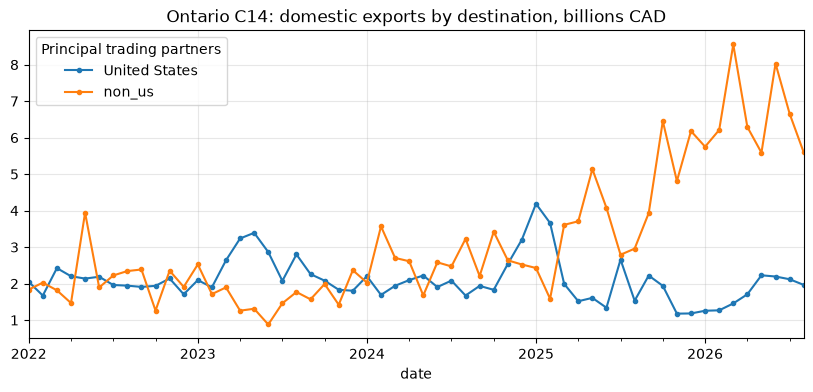

In [10]:
import matplotlib.pyplot as plt

c14 = df[(df['Trade'] == 'Domestic export')
         & (df['section'] == 'C14')
         & (df['GEO'] == 'Ontario')]

m = (c14.pivot_table(index='date',
                     columns='Principal trading partners',
                     values='value_cad') / 1e9)
m['non_us'] = m['All countries'] - m['United States']

print(m.round(2).tail(30).to_string())

m[['United States', 'non_us']].plot(figsize=(10, 4), marker='o', markersize=3)
plt.title('Ontario C14: domestic exports by destination, billions CAD')
plt.grid(alpha=0.3)
plt.show()

In [11]:
imp = df[(df['Trade'] == 'Import')
         & (df[prod_col] == 'Total of all merchandise')]

pi = imp.pivot_table(index=['date', 'GEO'],
                     columns='Principal trading partners',
                     values='value_cad').reset_index()

pi['non_us'] = pi['All countries'] - pi['United States']
pi['year'] = pi['date'].dt.year
pi['month'] = pi['date'].dt.month

yi = (pi[pi['month'] <= 8]
      .groupby(['GEO', 'year'])[['United States', 'non_us', 'All countries']]
      .sum() / 1e9)
yi['US share %'] = yi['United States'] / yi['All countries'] * 100

print('Jan-Aug imports, billions CAD')
print(yi.round(1))

print('\nYear-over-year change, %')
print((yi[['United States', 'non_us']]
       .groupby('GEO').pct_change() * 100).round(1))

Jan-Aug imports, billions CAD
Principal trading partners  United States  non_us  All countries  US share %
GEO     year                                                                
Canada  2022                        241.2   248.6          489.8        49.2
        2023                        251.9   252.4          504.4        49.9
        2024                        253.0   255.5          508.5        49.7
        2025                        247.6   283.0          530.6        46.7
        2026                        258.1   303.7          561.8        45.9
Ontario 2022                        153.9   137.1          291.0        52.9
        2023                        163.0   141.0          304.0        53.6
        2024                        162.5   144.2          306.7        53.0
        2025                        159.4   159.4          318.8        50.0
        2026                        166.6   172.3          338.9        49.2
Quebec  2022                         22.1    4

In [12]:
secm = df[(df['Trade'] == 'Import')
          & (df['section'] != 'Total')
          & (df['date'].dt.month <= 8)].copy()
secm['year'] = secm['date'].dt.year

qm = (secm.pivot_table(index=['GEO', 'section', 'year'],
                       columns='Principal trading partners',
                       values='value_cad', aggfunc='sum') / 1e9)
qm['non_us'] = qm['All countries'] - qm['United States']
nm = qm['non_us'].unstack('year')

for geo in ['Ontario', 'Quebec']:
    t = nm.loc[geo]
    out = pd.DataFrame({'2024': t[2024],
                        '2026': t[2026],
                        'change': t[2026] - t[2024]}).round(2)
    print(geo, '- non-U.S. imports, Jan-Aug, billions CAD')
    print(out.sort_values('change', ascending=False).to_string())
    print()

Ontario - non-U.S. imports, Jan-Aug, billions CAD
          2024   2026  change
section                      
C13       6.69  14.60    7.91
C18      28.75  34.27    5.52
C19      28.89  34.14    5.25
C22      37.00  41.30    4.30
C14       9.22  11.39    2.16
C17      15.44  17.02    1.59
C11       5.05   5.83    0.78
C15       6.09   6.37    0.28
C16       3.49   3.73    0.24
C12       0.20   0.29    0.09
C23       0.88   0.97    0.08
C21       2.45   2.41   -0.04

Quebec - non-U.S. imports, Jan-Aug, billions CAD
          2024   2026  change
section                      
C22      13.37  16.15    2.78
C14       5.36   7.30    1.94
C18       4.47   5.92    1.46
C17       5.71   7.05    1.34
C15       2.63   3.27    0.64
C19       2.28   2.85    0.58
C16       1.70   2.09    0.40
C11       2.68   2.86    0.19
C23       0.17   0.24    0.07
C13       2.62   2.45   -0.17
C12       1.73   1.55   -0.18
C21       5.35   5.05   -0.30



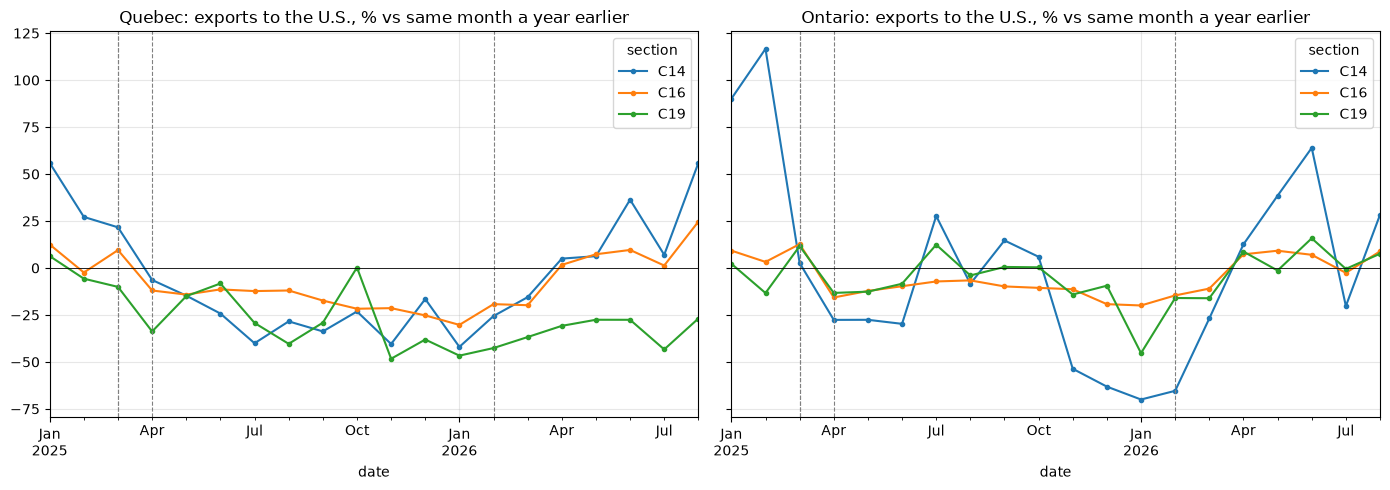

GEO        Ontario             Quebec            
section        C14   C16   C19    C14   C16   C19
date                                             
2025-01-01    90.0   9.0   2.0   56.0  12.0   6.0
2025-02-01   117.0   3.0 -13.0   27.0  -2.0  -6.0
2025-03-01     3.0  13.0  12.0   22.0  10.0 -10.0
2025-04-01   -28.0 -16.0 -13.0   -6.0 -12.0 -34.0
2025-05-01   -28.0 -12.0 -13.0  -15.0 -14.0 -15.0
2025-06-01   -30.0 -10.0  -8.0  -24.0 -11.0  -8.0
2025-07-01    28.0  -7.0  12.0  -40.0 -12.0 -29.0
2025-08-01    -8.0  -7.0  -4.0  -28.0 -12.0 -40.0
2025-09-01    15.0 -10.0   1.0  -34.0 -17.0 -29.0
2025-10-01     6.0 -11.0   0.0  -23.0 -22.0   0.0
2025-11-01   -54.0 -11.0 -14.0  -40.0 -21.0 -48.0
2025-12-01   -63.0 -19.0  -9.0  -17.0 -25.0 -38.0
2026-01-01   -70.0 -20.0 -45.0  -42.0 -30.0 -47.0
2026-02-01   -65.0 -15.0 -16.0  -26.0 -19.0 -43.0
2026-03-01   -27.0 -11.0 -16.0  -16.0 -20.0 -37.0
2026-04-01    13.0   7.0   9.0    5.0   2.0 -31.0
2026-05-01    38.0   9.0  -1.0    6.0   7.0 -28.0


In [13]:
import matplotlib.pyplot as plt

us = df[(df['Trade'] == 'Domestic export')
        & (df['Principal trading partners'] == 'United States')
        & (df['section'].isin(['C14', 'C16', 'C19']))
        & (df['GEO'].isin(['Quebec', 'Ontario']))]

pv = us.pivot_table(index='date', columns=['GEO', 'section'],
                    values='value_cad', aggfunc='sum')
yoy = (pv.pct_change(12) * 100).loc['2025-01-01':]

events = ['2025-03-04', '2025-03-12', '2025-04-03', '2026-02-24']

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, geo in zip(axes, ['Quebec', 'Ontario']):
    yoy[geo].plot(ax=ax, marker='o', markersize=3)
    for e in events:
        ax.axvline(pd.Timestamp(e), color='grey', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_title(geo + ': exports to the U.S., % vs same month a year earlier')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(yoy.round(0).to_string())

In [14]:
b = pv.loc['2023-01-01':'2024-12-31']
base = b.groupby(b.index.month).mean()

cur = pv.loc['2025-01-01':]
vs = (cur / base.loc[cur.index.month].values - 1) * 100

print(vs.round(0).to_string())

GEO        Ontario             Quebec            
section        C14   C16   C19    C14   C16   C19
date                                             
2025-01-01    95.0  12.0   2.0   50.0   8.0  21.0
2025-02-01   104.0   8.0  -7.0   36.0  -2.0  13.0
2025-03-01   -13.0  12.0   9.0   16.0   6.0   3.0
2025-04-01   -43.0 -10.0 -15.0   -6.0 -10.0 -21.0
2025-05-01   -43.0 -11.0 -15.0  -17.0 -14.0 -13.0
2025-06-01   -44.0  -7.0 -20.0  -22.0  -8.0   1.0
2025-07-01    28.0  -4.0  -5.0  -31.0  -8.0 -13.0
2025-08-01   -32.0 -12.0 -17.0  -34.0 -14.0 -30.0
2025-09-01     6.0  -7.0  -9.0  -31.0 -14.0 -17.0
2025-10-01    -1.0 -11.0  -6.0  -33.0 -21.0   8.0
2025-11-01   -46.0 -12.0 -24.0  -37.0 -19.0 -46.0
2025-12-01   -53.0 -17.0 -14.0  -10.0 -20.0 -37.0
2026-01-01   -42.0 -10.0 -44.0  -13.0 -24.0 -36.0
2026-02-01   -29.0  -8.0 -22.0    1.0 -21.0 -35.0
2026-03-01   -36.0   0.0  -8.0   -2.0 -15.0 -35.0
2026-04-01   -36.0  -3.0  -8.0   -1.0  -9.0 -45.0
2026-05-01   -21.0  -3.0 -16.0  -11.0  -8.0 -37.0


In [15]:
sector_map = {
    'C14': 'Targeted: Section 232 steel/aluminum',
    'C19': 'Targeted: Section 232 autos',
    'C16': 'Targeted: Section 232 lumber (from Oct 2025)',
    'C17': 'Partly covered: steel/aluminum derivatives',
    'C18': 'Partly covered: steel/aluminum derivatives',
    'C21': 'Watch: aerospace',
    'C11': 'Indirect: food and agri',
    'C12': 'Comparison: energy',
    'C13': 'Other', 'C15': 'Other', 'C22': 'Other',
    'C23': 'Exclude', 'Total': 'Total',
}
df['sector_group'] = df['section'].map(sector_map)
assert df['sector_group'].notna().all()

d = df[(df['Trade'] == 'Domestic export')
       & (df['Principal trading partners'] == 'United States')
       & (df['GEO'].isin(['Quebec', 'Ontario']))
       & (~df['sector_group'].isin(['Total', 'Exclude']))
       & (df['date'].dt.month <= 8)].copy()
d['year'] = d['date'].dt.year

g = (d.groupby(['GEO', 'sector_group', 'year'])['value_cad'].sum()
       .unstack('year') / 1e9)
g['base 23-24'] = g[[2023, 2024]].mean(axis=1)
g['2026 vs base %'] = (g[2026] / g['base 23-24'] - 1) * 100
print(g[[2023, 2024, 2025, 2026, 'base 23-24', '2026 vs base %']].round(2).to_string())

year                                                   2023   2024   2025   2026  base 23-24  2026 vs base %
GEO     sector_group                                                                                        
Ontario Comparison: energy                             1.75   1.75   1.87   2.16        1.75           23.27
        Indirect: food and agri                        4.26   4.30   4.31   4.72        4.28           10.39
        Other                                         32.65  32.12  32.07  34.37       32.39            6.12
        Partly covered: steel/aluminum derivatives    18.41  17.95  18.28  20.35       18.18           11.95
        Targeted: Section 232 autos                   47.89  43.26  41.62  38.69       45.58          -15.11
        Targeted: Section 232 lumber (from Oct 2025)   7.98   8.31   8.00   7.80        8.14           -4.21
        Targeted: Section 232 steel/aluminum          21.00  15.81  18.49  14.19       18.40          -22.89
        Watch: aero

In [17]:
import os
os.makedirs('../data/clean', exist_ok=True)
(pd.Series(sector_map, name='sector_group')
   .rename_axis('section').reset_index()
   .to_csv('../data/clean/sector_map.csv', index=False))